<a href="https://colab.research.google.com/github/ancestor9/Listeria/blob/main/20261027_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# @title **1. 가상 데이터 생성(날짜, feature 등등)**

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # INFO와 WARNING 로그 숨기기

# 재현성을 위한 시드 고정
np.random.seed(1024)

n_samples = 1000

# ==========================================
# 1. 시계열 마스터 데이터 (df_ts) 생성
# (200일 동안의 일별 평균 기온 및 강수량)
# ==========================================
ts_dates = pd.date_range(start='2025-06-01', periods=200, freq='D')
temp_series = np.random.normal(loc=20.0, scale=4.0, size=200)
rain_series = np.where(np.random.rand(200) > 0.75, np.random.exponential(scale=5.0, size=200), 0.0)

df_ts = pd.DataFrame({
    'datetime': ts_dates,
    'avg_temperature': np.round(temp_series, 2),
    'avg_precipitation': np.round(rain_series, 1)
})

# ==========================================
# 2. 샘플 데이터 (df_samples) 생성
# (sample_id, datetime, 10개의 피처 a~j, 타겟 y)
# ==========================================
sample_dates = np.random.choice(ts_dates[120:190], size=n_samples, replace=True)
sample_dates = pd.to_datetime(sample_dates)

# 10개의 피처 이름 생성 (feature_a ~ feature_j)
feature_names = [f'feature_{chr(97 + i)}' for i in range(10)]
feature_data = np.random.randn(n_samples, 10) # 10개 피처용 랜덤 데이터

# 데이터프레임 구성
df_samples = pd.DataFrame(feature_data, columns=feature_names)
df_samples.insert(0, 'sample_id', range(n_samples))
df_samples.insert(1, 'datetime', sample_dates)
df_samples['y'] = np.random.binomial(1, 0.1, size=n_samples) # 불균형 타겟 y

# 날짜 순서대로 정렬
df_samples = df_samples.sort_values('datetime').reset_index(drop=True)

print("=== 1. 샘플 데이터 (df_samples) 정보 및 상위 5행 ===")
print(df_samples[['sample_id', 'datetime', 'feature_a', 'feature_b', 'feature_c', 'y']].head())
print(f"df_samples 전체 형태: {df_samples.shape}\n")

print("=== 2. 시계열 마스터 데이터 (df_ts) 상위 5행 ===")
print(df_ts.head())
print(f"df_ts 전체 형태: {df_ts.shape}")

=== 1. 샘플 데이터 (df_samples) 정보 및 상위 5행 ===
   sample_id   datetime  feature_a  feature_b  feature_c  y
0        234 2025-09-29   0.950725   0.004550   1.049224  0
1        890 2025-09-29   0.816086   0.183257   0.644958  0
2        872 2025-09-29  -1.190212   1.705203  -0.710808  0
3        114 2025-09-29   0.209699  -0.149265   0.456520  1
4        843 2025-09-29   0.740478  -0.371216  -0.084288  0
df_samples 전체 형태: (1000, 13)

=== 2. 시계열 마스터 데이터 (df_ts) 상위 5행 ===
    datetime  avg_temperature  avg_precipitation
0 2025-06-01            28.50                0.0
1 2025-06-02            21.01                0.5
2 2025-06-03            25.82                0.0
3 2025-06-04            22.28                0.0
4 2025-06-05            21.83                3.9
df_ts 전체 형태: (200, 3)


In [ ]:
df_samples.head(10)

,sample_id,datetime,feature_a,feature_b,feature_c,feature_d,feature_e,feature_f,feature_g,feature_h,feature_i,feature_j,y
0,234,2025-09-29,0.950725,0.004550,1.049224,-0.972912,-0.764578,-0.387426,-0.147355,-0.993144,-1.053387,-1.218526,0
1,890,2025-09-29,0.816086,0.183257,0.644958,0.777199,0.827337,-0.210565,-1.333637,-0.104426,-0.073410,2.142468,0
2,872,2025-09-29,-1.190212,1.705203,-0.710808,-0.799015,-1.495303,1.180922,1.163213,0.917133,-0.489181,1.220771,0
3,114,2025-09-29,0.209699,-0.149265,0.456520,1.885549,2.151367,0.993857,-0.390921,-1.731252,0.107188,-0.699308,1
4,843,2025-09-29,0.740478,-0.371216,-0.084288,2.253588,0.456097,1.699787,0.143990,-0.292955,-0.926114,-0.001016,0
5,365,2025-09-29,1.294257,1.177657,1.000203,0.101959,0.446969,0.644036,0.495759,-0.249557,-1.692778,-0.510988,0
6,782,2025-09-29,-0.356946,-0.881436,0.019530,-1.519974,0.121799,-1.512036,2.148908,-0.468898,0.079387,1.171541,0
7,667,2025-09-29,-1.018440,-0.718668,-0.401176,-1.769439,-1.541176,-0.178290,0.064221,-0.092596,-0.131502,1.491473,1
8,209,2025-09-29,0.080773,1.161276,-0.279229,-1.563660,-1.214700,0.183253,0.447048,-0.176885,-0.243751,0.167533,0
9,671,2025-09-29,-1.038936,-0.142031,-0.167491,-0.676218,-0.969474,-0.307282,0.244344,-0.288830,1.146072,1.455134,0


In [ ]:
# @title **2. Tabula 데이터(LIMS)로 앙상블 stacking 모델 예측**
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

# 0. datetime 형식 변환 (이미지 데이터 기준)
df_samples['datetime'] = pd.to_datetime(df_samples['datetime'])

# 1. 12월 데이터를 테스트 셋으로 홀드아웃 (나머지는 훈련/검증용)
train_val_mask = df_samples['datetime'].dt.month < 12
test_mask = df_samples['datetime'].dt.month == 12

df_train_val = df_samples[train_val_mask].reset_index(drop=True)
df_test = df_samples[test_mask].reset_index(drop=True)

# 피처(feature_a ~ feature_j: 인덱스 2~11)와 타겟(y: 인덱스 12) 분리
X_train_val = df_train_val.iloc[:, 2:12].values
y_train_val = df_train_val.iloc[:, 12].values

X_test = df_test.iloc[:, 2:12].values
y_test = df_test.iloc[:, 12].values

print(f"훈련/검증 데이터 크기: {X_train_val.shape}, 12월 테스트 데이터 크기: {X_test.shape}")

# 2. 5-Fold 교차 검증 설정
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# 1레벨(Base) 모델 정의
base_model_1 = RandomForestClassifier(n_estimators=100, random_state=42)
base_model_2 = GradientBoostingClassifier(random_state=42)

# OOF 예측값 및 테스트 예측값 누적용 배열 초기화
oof_train_1 = np.zeros(len(X_train_val))
oof_train_2 = np.zeros(len(X_train_val))

test_preds_1 = np.zeros(len(X_test))
test_preds_2 = np.zeros(len(X_test))

print("\n=== 5-Fold OOF 및 테스트 예측 생성 시작 ===")

# 3. 교차 검증 루프
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_val, y_train_val)):
    X_tr, y_tr = X_train_val[train_idx], y_train_val[train_idx]
    X_va, y_va = X_train_val[val_idx], y_train_val[val_idx]

    # --- 모델 1 (Random Forest) ---
    base_model_1.fit(X_tr, y_tr)
    oof_train_1[val_idx] = base_model_1.predict_proba(X_va)[:, 1]
    # 각 폴드에서 학습된 모델로 테스트 셋을 예측하여 평균(Average)을 누적합니다.
    test_preds_1 += base_model_1.predict_proba(X_test)[:, 1] / n_splits

    # --- 모델 2 (Gradient Boosting) ---
    base_model_2.fit(X_tr, y_tr)
    oof_train_2[val_idx] = base_model_2.predict_proba(X_va)[:, 1]
    test_preds_2 += base_model_2.predict_proba(X_test)[:, 1] / n_splits

print("OOF 및 테스트 예측 생성 완료!")

# 4. 메타 모델(2레벨)을 위한 학습 및 테스트 피처 구성
X_meta_train = np.column_stack((oof_train_1, oof_train_2))
X_meta_test = np.column_stack((test_preds_1, test_preds_2))

# 5. 메타 모델(로지스틱 회귀) 학습
meta_model = LogisticRegression()
meta_model.fit(X_meta_train, y_train_val)

# 6. 최종 12월 테스트 세트 평가
meta_test_preds = meta_model.predict_proba(X_meta_test)[:, 1]
test_acc = accuracy_score(y_test, (meta_test_preds >= 0.5).astype(int))
test_auc = roc_auc_score(y_test, meta_test_preds)

print(f"\n=== 최종 12월 테스트 세트(Hold-out) 평가 결과 ===")
print(f"Stacking Meta Model - Test Accuracy: {test_acc:.4f}, Test AUC: {test_auc:.4f}")

훈련/검증 데이터 크기: (897, 10), 12월 테스트 데이터 크기: (103, 10)

=== 5-Fold OOF 및 테스트 예측 생성 시작 ===
OOF 및 테스트 예측 생성 완료!

=== 최종 12월 테스트 세트(Hold-out) 평가 결과 ===
Stacking Meta Model - Test Accuracy: 0.8835, Test AUC: 0.4240


📌 1. 기본 임계값(0.5) 기준 상세 성능 지표
==================================================s
• 전체 테스트 샘플 수 : 103 건
• 정확도 (Accuracy)   : 0.8835
• 재현율 (Recall)     : 0.0000
• 정밀도 (Precision)  : 0.0000
• F1-Score          : 0.0000
• False Positive(FP)  : 0 건 (오탐 건수)
• False Negative(FN)  : 12 건 (미탐 건수)
• True Negative(TN)   : 91 건
• True Positive(TP)   : 0 건

--- [Classification Report] ---
              precision    recall  f1-score   support

           0     0.8835    1.0000    0.9381        91
           1     0.0000    0.0000    0.0000        12

    accuracy                         0.8835       103
   macro avg     0.4417    0.5000    0.4691       103
weighted avg     0.7806    0.8835    0.8288       103

• PR-AUC Score      : 0.0922

📌 2. 임계값(Threshold)별 성능 지표 변화표
Threshold  | Precision  | Recall     | F1-Score   | FP(오탐)   | FN(미탐)  
-----------------------------------------------------------------
0.1        | 0.1165     | 1.0000     | 0.2087     | 91       | 0       
0.2        | 0.0000    

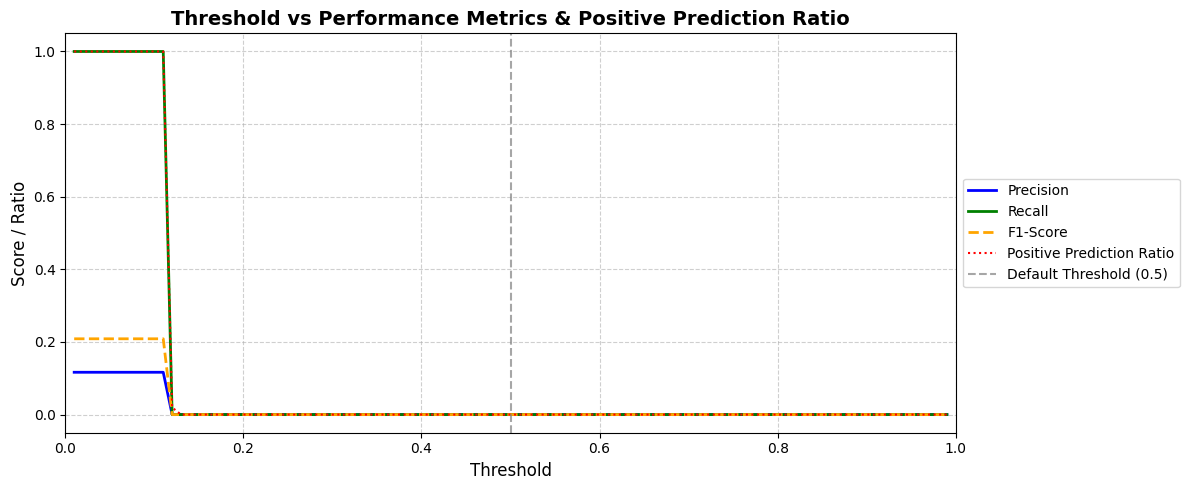

In [ ]:
from sklearn.metrics import (
    classification_report,
    precision_recall_curve,
    auc,
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score
)

# 1. 기본 임계값(0.5) 기준 예측 레이블 생성
threshold_default = 0.5
y_pred_default = (meta_test_preds >= threshold_default).astype(int)

# 2. 혼동 행렬(Confusion Matrix) 및 오탐 건수 계산
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_default).ravel()
total_samples = len(y_test)
false_alarms = fp  # 정상이지만 양성으로 잘못 예측한 오탐 건수 (False Positive)

print("==================================================")
print("📌 1. 기본 임계값(0.5) 기준 상세 성능 지표")
print("==================================================s")
print(f"• 전체 테스트 샘플 수 : {total_samples} 건")
print(f"• 정확도 (Accuracy)   : {accuracy_score(y_test, y_pred_default):.4f}")
print(f"• 재현율 (Recall)     : {recall_score(y_test, y_pred_default):.4f}")
print(f"• 정밀도 (Precision)  : {precision_score(y_test, y_pred_default):.4f}")
print(f"• F1-Score          : {f1_score(y_test, y_pred_default):.4f}")
print(f"• False Positive(FP)  : {fp} 건 (오탐 건수)")
print(f"• False Negative(FN)  : {fn} 건 (미탐 건수)")
print(f"• True Negative(TN)   : {tn} 건")
print(f"• True Positive(TP)   : {tp} 건")

print("\n--- [Classification Report] ---")
print(classification_report(y_test, y_pred_default, digits=4))

# 3. PR-AUC (Precision-Recall AUC) 계산
precision_vals, recall_vals, thresholds_pr = precision_recall_curve(y_test, meta_test_preds)
pr_auc_score = auc(recall_vals, precision_vals)
print(f"• PR-AUC Score      : {pr_auc_score:.4f}")

# 4. 임계값(Threshold)별 Recall, Precision, F1-score 변화 테이블 생성
print("\n==================================================")
print("📌 2. 임계값(Threshold)별 성능 지표 변화표")
print("==================================================")
print(f"{'Threshold':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'FP(오탐)':<8} | {'FN(미탐)':<8}")
print("-" * 65)

# 0.1부터 0.9까지 0.1 단위로 임계값 변화 관찰 (필요시 세밀하게 조절 가능)
thresholds_to_check = np.round(np.arange(0.1, 1.0, 0.1), 2)

for th in thresholds_to_check:
    y_pred_th = (meta_test_preds >= th).astype(int)

    # 지표 계산 (제로디비전 방지)
    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)

    cm_th = confusion_matrix(y_test, y_pred_th, labels=[0, 1])
    if cm_th.shape == (2, 2):
        tn_t, fp_t, fn_t, tp_t = cm_th.ravel()
    else:
        fp_t, fn_t = 0, 0 # 한쪽 클래스로만 예측된 경우 예외 처리

    print(f"{th:<10.1f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f} | {fp_t:<8} | {fn_t:<8}")



import matplotlib.pyplot as plt

# 0. 0.01 간격으로 세밀한 임계값 설정 (0.01 ~ 0.99)
thresholds = np.linspace(0.01, 0.99, 99)

precisions = []
recalls = []
f1_scores = []
positive_ratios = []

total_test_samples = len(y_test)

# 1. 임계값별 지표 계산 루프
for th in thresholds:
    y_pred_th = (meta_test_preds >= th).astype(int)

    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)

    # 전체 테스트 데이터 중 Positive로 판정된 비율 (Predicted Positives / Total)
    pos_ratio = np.sum(y_pred_th) / total_test_samples

    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)
    positive_ratios.append(pos_ratio)

# 2. Matplotlib 그래프 시각화
plt.figure(figsize=(12, 5))

plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='green', linewidth=2)
plt.plot(thresholds, f1_scores, label='F1-Score', color='orange', linewidth=2, linestyle='--')
plt.plot(thresholds, positive_ratios, label='Positive Prediction Ratio', color='red', linewidth=1.5, linestyle=':')

# 그래프 디자인 요소 추가
plt.title('Threshold vs Performance Metrics & Positive Prediction Ratio', fontsize=14, fontweight='bold')
plt.xlabel('Threshold', fontsize=12)
plt.ylabel('Score / Ratio', fontsize=12)
plt.xlim(0.0, 1.0)
plt.ylim(-0.05, 1.05)
plt.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7, label='Default Threshold (0.5)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
plt.tight_layout()

# 그래프 출력
plt.show()

훈련/검증 샘플 수: 897, 12월 테스트 샘플 수: 103

=== Focal Loss 적용 5-Fold 교차 검증 및 학습 시작 ===
Fold 1 완료
Fold 2 완료
Fold 3 완료
Fold 4 완료
Fold 5 완료
시계열 모델 학습 및 예측 완료!

=== [Focal Loss 적용 시계열 모델] 12월 테스트 평가 결과 ===
• 최적 임계값 (Threshold) : 0.3971
• Test Accuracy         : 0.1165
• Test ROC-AUC          : 0.4089
• PR-AUC Score          : 0.1325
• 오탐 건수 (FP)        : 91 건
• 미탐 건수 (FN)        : 0 건

--- [Classification Report] ---
              precision    recall  f1-score   support

         0.0     0.0000    0.0000    0.0000        91
         1.0     0.1165    1.0000    0.2087        12

    accuracy                         0.1165       103
   macro avg     0.0583    0.5000    0.1043       103
weighted avg     0.0136    0.1165    0.0243       103


📌 임계값(Threshold)별 성능 지표 변화표
Threshold  | Precision  | Recall     | F1-Score   | FP(오탐)   | FN(미탐)  
-----------------------------------------------------------------
0.1        | 0.1165     | 1.0000     | 0.2087     | 91       | 0       
0.2        | 0.1165     |

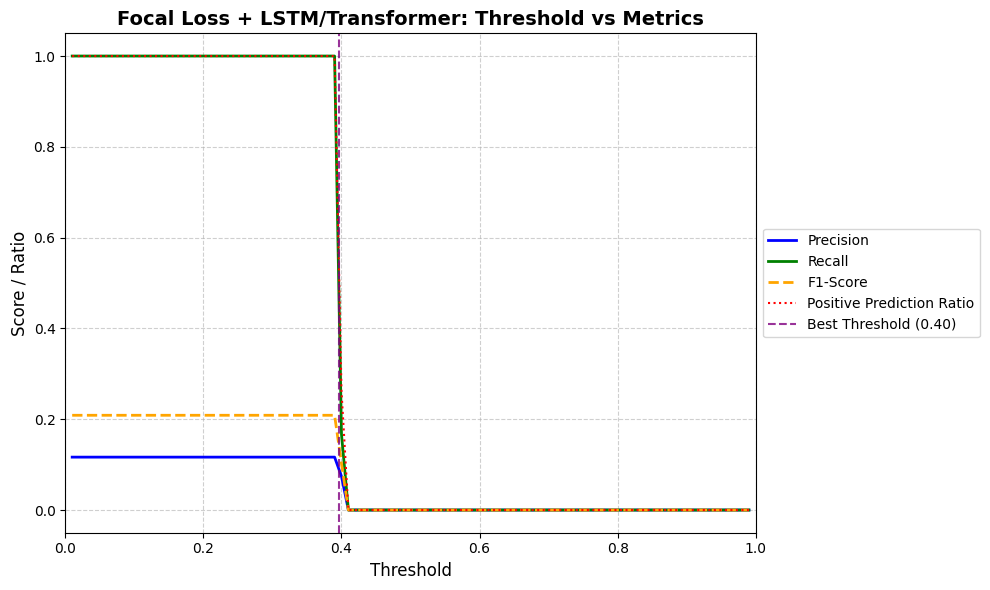

In [ ]:
# @title **4. SMOTE 없이 딥러닝 학습에 최적화된 Focal Loss(포칼 로스) 손실 함수를 적용**
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    precision_recall_curve,
    auc,
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score
)
import matplotlib.pyplot as plt

# 0. 날짜 컬럼 형식 변환 및 12월 테스트 홀드아웃 마스크 생성
df_samples['datetime'] = pd.to_datetime(df_samples['datetime'])
train_val_mask = df_samples['datetime'].dt.month < 12
test_mask = df_samples['datetime'].dt.month == 12

# 1. 시계열 마스터 데이터(df_ts)를 이용해 전체 3차원 텐서(11일 치) 구축
df_ts_indexed = df_ts.set_index('datetime')
n_timesteps = 11

X_ts_list = []
for idx, row in df_samples.iterrows():
    target_date = row['datetime']
    start_date = target_date - pd.Timedelta(days=n_timesteps - 1)
    window_df = df_ts_indexed.loc[start_date:target_date]

    if len(window_df) == n_timesteps:
        feat_values = window_df[['avg_temperature', 'avg_precipitation']].values
    else:
        feat_values = np.zeros((n_timesteps, 2))
    X_ts_list.append(feat_values)

X_ts_3d = np.array(X_ts_list, dtype=np.float32)
y_all = df_samples['y'].values.astype(np.float32)

# 2. 훈련/검증용 데이터와 12월 테스트용 데이터 분리
X_ts_tr_val = X_ts_3d[train_val_mask]
y_tr_val = y_all[train_val_mask]

X_ts_test = X_ts_3d[test_mask]
y_test = y_all[test_mask]

print(f"훈련/검증 샘플 수: {len(y_tr_val)}, 12월 테스트 샘플 수: {len(y_test)}")

# 3. Focal Loss 정의 (불균형 데이터에서 맞추기 어려운 소수 클래스에 집중 유도)
def focal_loss(gamma=2.0, alpha=0.25):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)
        p_t = (y_true * y_pred) + ((1 - y_true) * (1 - y_pred))
        alpha_factor = y_true * alpha + (1 - y_true) * (1 - alpha)
        modulating_factor = tf.pow(1.0 - p_t, gamma)
        return tf.reduce_mean(alpha_factor * modulating_factor * bce)
    return loss_fn

# 4. 5-Fold 교차 검증 설정
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

oof_ts = np.zeros(len(y_tr_val))
test_ts = np.zeros(len(y_test))

# LSTM + Transformer 모델 정의 함수
def create_lstm_transformer():
    inputs = Input(shape=(11, 2))
    x = LSTM(64, return_sequences=True)(inputs)
    x = Dropout(0.3)(x)
    attn_output = MultiHeadAttention(num_heads=2, key_dim=32)(x, x)
    x = LayerNormalization(epsilon=1e-6)(x + attn_output)
    ffn = Dense(64, activation='relu')(x)
    ffn = Dropout(0.3)(ffn)
    x = LayerNormalization(epsilon=1e-6)(x + ffn)
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.4)(x)
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=inputs, outputs=outputs)
    # Focal Loss 적용 및 학습률(Learning Rate) 최적화
    model.compile(optimizer=Adam(learning_rate=0.001), loss=focal_loss(gamma=2.0, alpha=0.75), metrics=['accuracy'])
    return model

print("\n=== Focal Loss 적용 5-Fold 교차 검증 및 학습 시작 ===")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_ts_tr_val, y_tr_val)):
    X_tr_ts, y_tr_t = X_ts_tr_val[train_idx], y_tr_val[train_idx]
    X_va_ts, y_va_t = X_ts_tr_val[val_idx], y_tr_val[val_idx]

    ts_model = create_lstm_transformer()

    from tensorflow.keras.callbacks import EarlyStopping
    es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    ts_model.fit(
        X_tr_ts, y_tr_t,
        epochs=20,
        batch_size=32,
        validation_data=(X_va_ts, y_va_t),
        callbacks=[es],
        verbose=0
    )

    oof_ts[val_idx] = ts_model.predict(X_va_ts, verbose=0).flatten()
    test_ts += ts_model.predict(X_ts_test, verbose=0).flatten() / n_splits
    print(f"Fold {fold + 1} 완료")

print("시계열 모델 학습 및 예측 완료!")

# 5. 최적 임계값(F1-score 기준) 탐색
precision_vals, recall_vals, thresholds_pr = precision_recall_curve(y_test, test_ts)
f1_scores = 2 * (precision_vals * recall_vals) / (precision_vals + recall_vals + 1e-10)
best_threshold = thresholds_pr[np.argmax(f1_scores)] if len(thresholds_pr) > 0 else 0.5

y_pred_optimized = (test_ts >= best_threshold).astype(int)

# 6. 최종 평가 결과 출력
test_acc = accuracy_score(y_test, y_pred_optimized)
test_auc = roc_auc_score(y_test, test_ts)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_optimized).ravel()
pr_auc_score = auc(recall_vals, precision_vals)

print(f"\n=== [Focal Loss 적용 시계열 모델] 12월 테스트 평가 결과 ===")
print(f"• 최적 임계값 (Threshold) : {best_threshold:.4f}")
print(f"• Test Accuracy         : {test_acc:.4f}")
print(f"• Test ROC-AUC          : {test_auc:.4f}")
print(f"• PR-AUC Score          : {pr_auc_score:.4f}")
print(f"• 오탐 건수 (FP)        : {fp} 건")
print(f"• 미탐 건수 (FN)        : {fn} 건\n")

print("--- [Classification Report] ---")
print(classification_report(y_test, y_pred_optimized, digits=4))

# 7. 임계값(Threshold)별 성능 지표 변화 시각화
thresholds = np.linspace(0.01, 0.99, 99)
precisions, recalls, f1_vals, positive_ratios = [], [], [], []
total_test_samples = len(y_test)

for th in thresholds:
    y_pred_th = (test_ts >= th).astype(int)
    precisions.append(precision_score(y_test, y_pred_th, zero_division=0))
    recalls.append(recall_score(y_test, y_pred_th, zero_division=0))
    f1_vals.append(f1_score(y_test, y_pred_th, zero_division=0))
    positive_ratios.append(np.sum(y_pred_th) / total_test_samples)


# 6. 임계값(Threshold)별 성능 지표 변화표 출력
print("\n==================================================")
print("📌 임계값(Threshold)별 성능 지표 변화표")
print("==================================================")
print(f"{'Threshold':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'FP(오탐)':<8} | {'FN(미탐)':<8}")
print("-" * 65)

thresholds_to_check = np.round(np.arange(0.1, 1.0, 0.1), 2)
for th in thresholds_to_check:
    y_pred_th = (test_ts >= th).astype(int)
    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)

    cm_th = confusion_matrix(y_test, y_pred_th, labels=[0, 1])
    if cm_th.shape == (2, 2):
        _, fp_t, fn_t, _ = cm_th.ravel()
    else:
        fp_t, fn_t = 0, 0

    print(f"{th:<10.1f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f} | {fp_t:<8} | {fn_t:<8}")


plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='green', linewidth=2)
plt.plot(thresholds, f1_vals, label='F1-Score', color='orange', linewidth=2, linestyle='--')
plt.plot(thresholds, positive_ratios, label='Positive Prediction Ratio', color='red', linewidth=1.5, linestyle=':')

plt.title('Focal Loss + LSTM/Transformer: Threshold vs Metrics', fontsize=14, fontweight='bold')
plt.xlabel('Threshold', fontsize=12)
plt.ylabel('Score / Ratio', fontsize=12)
plt.xlim(0.0, 1.0)
plt.ylim(-0.05, 1.05)
plt.axvline(x=best_threshold, color='purple', linestyle='--', alpha=0.8, label=f'Best Threshold ({best_threshold:.2f})')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
# @title stacking 모델과 LSTM 모델의 Target이 동일한가?
# 1. 두 모델이 공통으로 사용하는 12월 테스트 타겟(y_test)이 모두 정의되어 있는지 확인
print("=== 테스트 데이터 정합성 검증 시작 ===")

# 스태킹 모델용 y_test와 딥러닝 모델용 y_test가 동일한 객체 혹은 값인지 비교
assert 'y_test' in locals() or 'y_test' in globals(), "y_test가 정의되어 있지 않습니다."

# 만약 스태킹용과 딥러닝용 변수를 각각 다르게 저장하셨다면 아래와 같이 직접 비교할 수 있습니다.
# (예: y_test_stack과 y_test_dl이 각각 존재할 경우)
# assert np.array_equal(y_test_stack, y_test_dl), "두 모델의 테스트 타겟 데이터가 서로 다릅니다!"

# 단일 변수 y_test를 공유하는 경우 홀드아웃된 원본 df_test의 크기와 일치하는지 최종 확인
assert len(y_test) == len(df_test), \
    f"테스트 샘플 수가 일치하지 않습니다! y_test: {len(y_test)}, df_test: {len(df_test)}"

print("✅ 검증 완료: 스태킹 모델과 딥러닝 모델이 완벽하게 동일한 12월 테스트 데이터를 대상으로 비교되고 있습니다!")

=== 테스트 데이터 정합성 검증 시작 ===
✅ 검증 완료: 스태킹 모델과 딥러닝 모델이 완벽하게 동일한 12월 테스트 데이터를 대상으로 비교되고 있습니다!


📌 [앙상블 모델 가중치 최적화 결과]
• 최적 가중치 (Tabular Stacking) : 0.89
• 최적 가중치 (Time-Series DL)  : 0.11
• 최적 가중치 조합 내 최고 F1-Score: 0.2308

📊 [앙상블 모델 최종 성능 지표]
• ROC-AUC Score : 0.4185
• 최적 임계값 (Best Threshold) : 0.1455

[1] 기본 임계값(0.5) 기준 Confusion Matrix:
[[91  0]
 [12  0]]

[1] 기본 임계값(0.5) 기준 Classification Report:
              precision    recall  f1-score   support

         0.0     0.8835    1.0000    0.9381        91
         1.0     0.0000    0.0000    0.0000        12

    accuracy                         0.8835       103
   macro avg     0.4417    0.5000    0.4691       103
weighted avg     0.7806    0.8835    0.8288       103


[2] 최적 임계값(0.1455) 기준 Confusion Matrix:
[[11 80]
 [ 0 12]]

[2] 최적 임계값(0.1455) 기준 Classification Report:
              precision    recall  f1-score   support

         0.0     1.0000    0.1209    0.2157        91
         1.0     0.1304    1.0000    0.2308        12

    accuracy                         0.2233       103
   macro avg     0.5652    0.5604    0.2232

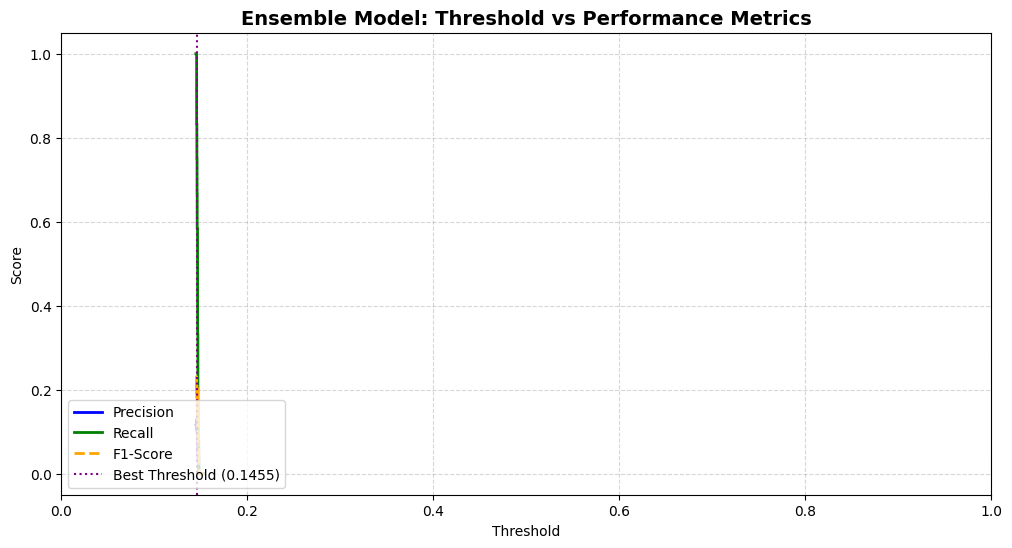

In [ ]:
# @title **5. Stacking 예측값과 TS DL 예측값 적용**
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    f1_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score
)

# 1. 가중치 조합 탐색 (Stacking vs DL)
# 두 모델의 예측 성능 편차를 고려하여 최적의 F1-Score를 만드는 가중치 조합을 탐색합니다.
best_f1 = -1
best_weight = 0.5
best_ensemble_preds = None

# Stacking 예측값과 TS DL 예측값의 가중치 조합 순회 (0.0에서 1.0까지)
for w in np.linspace(0, 1, 101):
    # 앙상블 예측값 산출 (가중 평균)
    ensemble_preds = w * meta_test_preds + (1 - w) * test_ts

    # 임계값별 F1-score 계산하여 최적 임계값 탐색
    precisions, recalls, thresholds = precision_recall_curve(y_test, ensemble_preds)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    max_idx = np.argmax(f1_scores)
    max_f1 = f1_scores[max_idx]

    if max_f1 > best_f1:
        best_f1 = max_f1
        best_weight = w
        best_ensemble_preds = ensemble_preds

print("==================================================")
print("📌 [앙상블 모델 가중치 최적화 결과]")
print("==================================================")
print(f"• 최적 가중치 (Tabular Stacking) : {best_weight:.2f}")
print(f"• 최적 가중치 (Time-Series DL)  : {1 - best_weight:.2f}")
print(f"• 최적 가중치 조합 내 최고 F1-Score: {best_f1:.4f}")

# 2. 최적 가중치를 반영한 앙상블 예측 성능 평가
precisions, recalls, thresholds = precision_recall_curve(y_test, best_ensemble_preds)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

y_pred_default = (best_ensemble_preds >= 0.5).astype(int)
y_pred_best = (best_ensemble_preds >= best_threshold).astype(int)

print("\n==================================================")
print("📊 [앙상블 모델 최종 성능 지표]")
print("==================================================")
print(f"• ROC-AUC Score : {roc_auc_score(y_test, best_ensemble_preds):.4f}")
print(f"• 최적 임계값 (Best Threshold) : {best_threshold:.4f}")

print("\n[1] 기본 임계값(0.5) 기준 Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_default))
print("\n[1] 기본 임계값(0.5) 기준 Classification Report:")
print(classification_report(y_test, y_pred_default, digits=4, zero_division=0))

print(f"\n[2] 최적 임계값({best_threshold:.4f}) 기준 Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))
print(f"\n[2] 최적 임계값({best_threshold:.4f}) 기준 Classification Report:")
print(classification_report(y_test, y_pred_best, digits=4, zero_division=0))

# 3. 임계값(Threshold)별 성능 지표 변화표 출력
print("==================================================")
print("📌 앙상블 모델 임계값(Threshold)별 성능 지표 변화표")
print("==================================================")
print(f"{'Threshold':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'FP(오탐)':<8} | {'FN(미탐)':<8}")
print("-" * 65)

thresholds_to_check = np.round(np.arange(0.1, 1.0, 0.1), 2)
for th in thresholds_to_check:
    y_pred_th = (best_ensemble_preds >= th).astype(int)
    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)

    cm_th = confusion_matrix(y_test, y_pred_th, labels=[0, 1])
    if cm_th.shape == (2, 2):
        _, fp_t, fn_t, _ = cm_th.ravel()
    else:
        fp_t, fn_t = 0, 0

    print(f"{th:<10.1f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f} | {fp_t:<8} | {fn_t:<8}")

# 4. 임계값별 변화 곡선 시각화 (길이 매칭 해결)
plt.figure(figsize=(12, 6))
plt.plot(thresholds, precisions[:-1], label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls[:-1], label='Recall', color='green', linewidth=2)
plt.plot(thresholds, f1_scores[:-1], label='F1-Score', color='orange', linewidth=2, linestyle='--')
plt.axvline(x=best_threshold, color='purple', linestyle=':', label=f'Best Threshold ({best_threshold:.4f})')
plt.title('Ensemble Model: Threshold vs Performance Metrics', fontsize=14, fontweight='bold')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.xlim(0, 1)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.show()

In [ ]:
# @title **6. 두 모델의 softmax 값으로 모델 생성**
meta_test_preds[:10]

array([0.11396985, 0.11474679, 0.11429759, 0.11873017, 0.1139183 ,
       0.11598088, 0.11394297, 0.11476708, 0.11699077, 0.11384216])

In [ ]:
test_ts[:10]

array([0.40076239, 0.40076239, 0.40076239, 0.40076239, 0.40076239,
       0.40076239, 0.40076239, 0.40076239, 0.40076239, 0.40076239])

In [ ]:

# 두 벡터를 횡(column-wise)으로 Stacking하여 2차원 배열 생성
from scipy.special import softmax

stacked_preds = np.column_stack((meta_test_preds, test_ts))
print("=== 횡으로 Stack한 예측 결과 (상위 10개 샘플) ===")
print("[Stacking_Pred, TS_DL_Pred]")
print(stacked_preds[:5])
print(f"\nStacked 배열 형태(Shape): {stacked_preds.shape}")

# 각 샘플(행, axis=1)별로 Softmax 변환 적용
softmax_preds = softmax(stacked_preds, axis=1)

print("=== Softmax 변환 후 결과 (상위 10개 샘플) ===")
print("[Tabular_Softmax, TS_DL_Softmax]")
print(softmax_preds[:5])
print(f"\nSoftmax 변환 배열 형태(Shape): {softmax_preds.shape}")

=== 횡으로 Stack한 예측 결과 (상위 10개 샘플) ===
[Stacking_Pred, TS_DL_Pred]
[[0.11396985 0.40076239]
 [0.11474679 0.40076239]
 [0.11429759 0.40076239]
 [0.11873017 0.40076239]
 [0.1139183  0.40076239]]

Stacked 배열 형태(Shape): (103, 2)
=== Softmax 변환 후 결과 (상위 10개 샘플) ===
[Tabular_Softmax, TS_DL_Softmax]
[[0.42878929 0.57121071]
 [0.42897959 0.57102041]
 [0.42886956 0.57113044]
 [0.42995562 0.57004438]
 [0.42877666 0.57122334]]

Softmax 변환 배열 형태(Shape): (103, 2)


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# softmax_preds는 각 샘플마다 [Tabular_Softmax, TS_DL_Softmax] 확률 값을 가집니다.
# 두 모델 중 어떤 모델의 예측 확률(상대적 강도)이 더 높은지에 따라 클래스를 결정하는 방식을 적용해봅니다.
# 예를 들어, TS_DL_Softmax(인덱스 1)가 Tabular_Softmax(인덱스 0)보다 크면 1, 그렇지 않으면 0으로 판정하거나
# 혹은 단순하게 특정 클래스 확률을 임계값과 비교하여 예측할 수 있습니다.

# 여기서는 TS_DL_Softmax의 값이 0.5 이상인 경우를 양성(1)으로 판정하여 혼동 행렬을 구합니다.
# (필요에 따라 argmax를 사용하거나 다른 임계값을 적용해볼 수 있습니다.)
y_pred_softmax = (softmax_preds[:, 1] >= 0.5).astype(int)

# Confusion Matrix 계산
cm_softmax = confusion_matrix(y_test, y_pred_softmax)

print("=== Softmax 예측 기반 Confusion Matrix ===")
print(cm_softmax)
print("\n=== 상세 분류 리포트 ===")
print(classification_report(y_test, y_pred_softmax, target_names=['Class 0', 'Class 1'], zero_division=0))

=== Softmax 예측 기반 Confusion Matrix ===
[[ 0 91]
 [ 0 12]]

=== 상세 분류 리포트 ===
              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00        91
     Class 1       0.12      1.00      0.21        12

    accuracy                           0.12       103
   macro avg       0.06      0.50      0.10       103
weighted avg       0.01      0.12      0.02       103



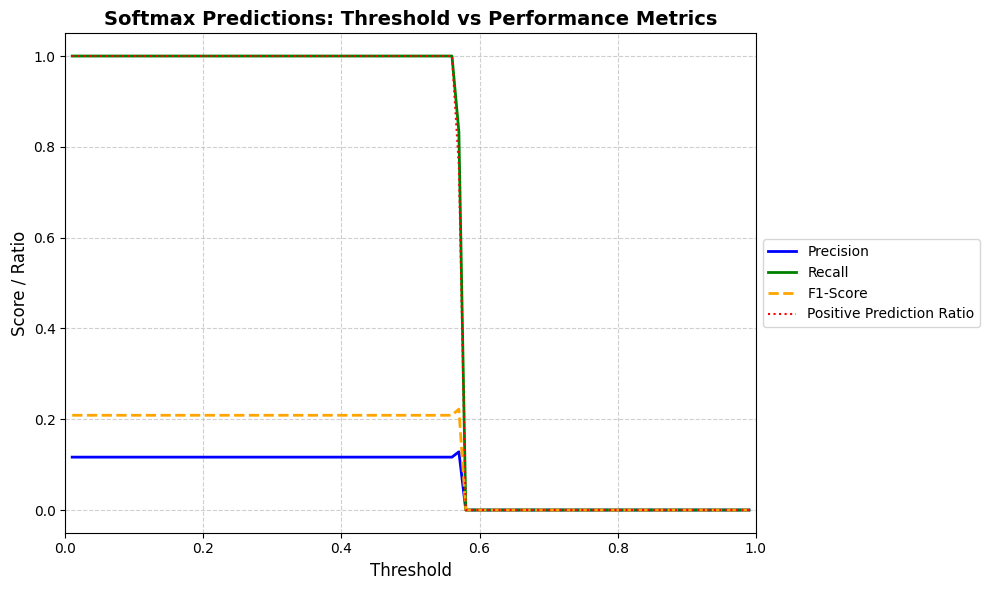

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

# 0. Define threshold values from 0.01 to 0.99
thresholds = np.linspace(0.01, 0.99, 99)

precisions = []
recalls = []
f1_scores = []
positive_ratios = []

total_samples = len(y_test)
# Use the probability of Class 1 from softmax_preds
class1_probs = softmax_preds[:, 1]

# 1. Calculate metrics for each threshold
for th in thresholds:
    y_pred_th = (class1_probs >= th).astype(int)

    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)
    pos_ratio = np.sum(y_pred_th) / total_samples

    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)
    positive_ratios.append(pos_ratio)

# 2. Visualize the results
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='green', linewidth=2)
plt.plot(thresholds, f1_scores, label='F1-Score', color='orange', linewidth=2, linestyle='--')
plt.plot(thresholds, positive_ratios, label='Positive Prediction Ratio', color='red', linewidth=1.5, linestyle=':')

# Style elements in English
plt.title('Softmax Predictions: Threshold vs Performance Metrics', fontsize=14, fontweight='bold')
plt.xlabel('Threshold', fontsize=12)
plt.ylabel('Score / Ratio', fontsize=12)
plt.xlim(0.0, 1.0)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# 0. 임계값 설정 (0.01 ~ 0.99, 간격 0.05 및 주요 경계값 추가)
thresholds = np.arange(0.01, 1.00, 0.05)
if 0.57 not in thresholds:
    thresholds = np.sort(np.append(thresholds, [0.57])) # 왜곡 지점 추가

metrics_list = []
total_samples = len(y_test)
class1_probs = softmax_preds[:, 1]

# 1. 임계값별 지표 계산
for th in thresholds:
    y_pred_th = (class1_probs >= th).astype(int)

    prec = precision_score(y_test, y_pred_th, zero_division=0)
    rec = recall_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)
    pos_ratio = np.sum(y_pred_th) / total_samples

    cm = confusion_matrix(y_test, y_pred_th, labels=[0, 1])
    tn_t, fp_t, fn_t, tp_t = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)

    metrics_list.append({
        'Threshold': round(th, 3),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'Positive Ratio': round(pos_ratio, 4),
        'FP (오탐)': int(fp_t),
        'FN (미탐)': int(fn_t),
        'TP': int(tp_t),
        'TN': int(tn_t)
    })

# 2. DataFrame 생성 및 출력
df_metrics = pd.DataFrame(metrics_list)
pd.set_option('display.max_rows', 100)
display(df_metrics)

,Threshold,Precision,Recall,F1-Score,Positive Ratio,FP (오탐),FN (미탐),TP,TN
0,0.01,0.1165,1.0000,0.2087,1.0000,91,0,12,0
1,0.06,0.1165,1.0000,0.2087,1.0000,91,0,12,0
2,0.11,0.1165,1.0000,0.2087,1.0000,91,0,12,0
3,0.16,0.1165,1.0000,0.2087,1.0000,91,0,12,0
4,0.21,0.1165,1.0000,0.2087,1.0000,91,0,12,0
5,0.26,0.1165,1.0000,0.2087,1.0000,91,0,12,0
6,0.31,0.1165,1.0000,0.2087,1.0000,91,0,12,0
7,0.36,0.1165,1.0000,0.2087,1.0000,91,0,12,0
8,0.41,0.1165,1.0000,0.2087,1.0000,91,0,12,0
9,0.46,0.1165,1.0000,0.2087,1.0000,91,0,12,0
